# NIDS par Deep Learning — CIC-IDS2017

Détection d'intrusions réseau avec un DNN (réseau de neurones dense),
comparé à un Random Forest. Dataset : CIC-IDS2017 (8 fichiers CSV).

Plan :
1. Environnement et données
2. Chargement et nettoyage
3. Création des étiquettes (binaire et multiclasse)
4. Découpage train/val/test et normalisation
5. DNN binaire (Normal/Attaque)
6. Baseline Random Forest
7. Réglage du seuil de décision
8. DNN multiclasse — essais successifs
9. Analyse d'erreurs (matrice de confusion)
10. Sauvegarde du modèle final

## 1. Connexion à Google Drive
Donne accès aux fichiers CIC-IDS2017 stockés sur Drive,
et permettra d'y sauvegarder le modèle entraîné.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Vérification de l'environnement
Versions de Python, TensorFlow, Pandas, et présence d'un GPU.

In [ ]:
import sys, tensorflow as tf, pandas as pd, sklearn
print("Python:",sys.version.split()[0])
print("TensorFlow:",tf.__version__)
print("Pandas:",pd.__version__)
print("GPU:",tf.config.list_physical_devices('GPU'))

Python: 3.13.15
TensorFlow: 2.21.0
Pandas: 2.2.3
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Vérification des données sur Drive
Liste les 8 fichiers CSV de CIC-IDS2017 déjà présents dans le dossier.

In [ ]:
!ls -lh "/content/drive/MyDrive/project/data/raw"

total 844M
-rw------- 1 root root  74M Oct 19 06:06 Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
-rw------- 1 root root  74M Oct 19 06:06 Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
-rw------- 1 root root  56M Oct 19 06:07 Friday-WorkingHours-Morning.pcap_ISCX.csv
-rw------- 1 root root 169M Oct 19 06:07 Monday-WorkingHours.pcap_ISCX.csv
-rw------- 1 root root  80M Oct 19 06:07 Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
-rw------- 1 root root  50M Oct 19 06:07 Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
-rw------- 1 root root 129M Oct 19 06:07 Tuesday-WorkingHours.pcap_ISCX.csv
-rw------- 1 root root 215M Oct 19 06:07 Wednesday-workingHours.pcap_ISCX.csv


## 4. Chargement et fusion des 8 fichiers
Chaque fichier correspond à un jour de capture. On nettoie les noms
de colonnes (espaces) et on fusionne le tout en un seul tableau.


In [ ]:
import pandas as pd, numpy as np, glob, gc

DATA_DIR  = "/content/drive/MyDrive/project/data/raw/"
MODEL_DIR = "/content/drive/MyDrive/project/models/"

import os
os.makedirs(MODEL_DIR, exist_ok=True)

files = sorted(glob.glob(DATA_DIR + "*.csv"))
print(len(files), "fichiers trouvés")

dfs = []
for f in files:
    d = pd.read_csv(f, encoding="latin-1", low_memory=False)
    d.columns = d.columns.str.strip()
    dfs.append(d)
    print(f.split("/")[-1], d.shape)

df = pd.concat(dfs, ignore_index=True)
del dfs; gc.collect()

print("\nTotal brut :", df.shape)

8 fichiers trouvés
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (225745, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (286467, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv (191033, 79)
Monday-WorkingHours.pcap_ISCX.csv (529918, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (288602, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (170366, 79)
Tuesday-WorkingHours.pcap_ISCX.csv (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv (692703, 79)

Total brut : (2830743, 79)


## 5. Nettoyage des données
- Suppression de la colonne dupliquée `Fwd Header Length.1`
- Valeurs infinies → NaN, puis suppression des lignes NaN
- Suppression des doublons (évite la fuite de données train/test)
- Conversion en float32 (économie de mémoire)


In [ ]:
# 1. Supprimer la colonne en double si elle existe
df = df.drop(columns=["Fwd Header Length.1"], errors="ignore")

# 2. Valeurs infinies -> NaN, puis suppression
df.replace([np.inf, -np.inf], np.nan, inplace=True)
print("Lignes avec NaN :", df.isna().any(axis=1).sum())
df.dropna(inplace=True)

# 3. Doublons
avant = len(df)
df.drop_duplicates(inplace=True)
print("Doublons supprimés :", avant - len(df))

# 4. Économie de mémoire
for c in df.select_dtypes("float64").columns:
    df[c] = df[c].astype("float32")
for c in df.select_dtypes("int64").columns:
    df[c] = pd.to_numeric(df[c], downcast="integer")

print("\nTaille finale :", df.shape)
print(df["Label"].value_counts())

Lignes avec NaN : 2867
Doublons supprimés : 307078

Taille finale : (2520798, 78)
Label
BENIGN                          2095057
DoS Hulk                         172846
DDoS                             128014
PortScan                          90694
DoS GoldenEye                     10286
FTP-Patator                        5931
DoS slowloris                      5385
DoS Slowhttptest                   5228
SSH-Patator                        3219
Bot                                1948
Web Attack ï¿½ Brute Force         1470
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


## 6. Création des étiquettes
- **y_bin** : 0 = Normal (BENIGN), 1 = Attaque
- **y_multi** : 7 familles (Normal, DoS, DDoS, PortScan, BruteForce,
  Bot, WebAttack). Infiltration et Heartbleed (47 lignes) sont exclues,
  trop rares pour être apprises.

In [ ]:
# Normaliser les labels (caractère mal décodé)
df["Label"] = df["Label"].str.replace("ï¿½", "-", regex=False)
df["Label"] = df["Label"].str.replace(r"\s+", " ", regex=True).str.strip()

# --- Binaire : 0 = normal, 1 = attaque ---
df["y_bin"] = (df["Label"] != "BENIGN").astype("int8")

# --- Multiclasse : regroupement des familles ---
mapping = {
    "BENIGN": "Normal",
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS",
    "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
    "DDoS": "DDoS",
    "PortScan": "PortScan",
    "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce",
    "Bot": "Bot",
    "Web Attack - Brute Force": "WebAttack",
    "Web Attack - XSS": "WebAttack",
    "Web Attack - Sql Injection": "WebAttack",
}
df["y_multi"] = df["Label"].map(mapping)

# Infiltration et Heartbleed : trop rares (47 lignes) -> retirés du multiclasse
print("Classes non mappées :", df.loc[df["y_multi"].isna(), "Label"].unique())

print("\nBinaire :")
print(df["y_bin"].value_counts(normalize=True).round(4))
print("\nMulticlasse :")
print(df["y_multi"].value_counts())

Classes non mappées : ['Infiltration' 'Heartbleed']

Binaire :
y_bin
0    0.8311
1    0.1689
Name: proportion, dtype: float64

Multiclasse :
y_multi
Normal        2095057
DoS            193745
DDoS           128014
PortScan        90694
BruteForce       9150
WebAttack        2143
Bot              1948
Name: count, dtype: int64


## 7. Découpage et normalisation
Split stratifié 70% train / 15% validation / 15% test.
Le `StandardScaler` est ajusté **uniquement sur le train**,
pour éviter toute fuite de données.

8 colonnes constantes retirées → 69 features retenues.
Le scaler et la liste des colonnes sont sauvegardés (nécessaires
pour réutiliser le modèle plus tard, ex. sur un trafic GNS3).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

# Features : toutes les colonnes numériques sauf étiquettes
feature_cols = [c for c in df.columns if c not in ["Label", "y_bin", "y_multi"]]

# Retirer les colonnes constantes (aucune information)
const_cols = [c for c in feature_cols if df[c].nunique() <= 1]
print("Colonnes constantes retirées :", const_cols)
feature_cols = [c for c in feature_cols if c not in const_cols]

X = df[feature_cols].astype("float32")
y = df["y_bin"]

# 70 % train / 15 % validation / 15 % test (stratifié)
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

# Normalisation : ajustée sur le train UNIQUEMENT
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype("float32")
X_val   = scaler.transform(X_val).astype("float32")
X_test  = scaler.transform(X_test).astype("float32")

# Sauvegarde pour la partie GNS3
joblib.dump(scaler, MODEL_DIR + "scaler.pkl")
joblib.dump(feature_cols, MODEL_DIR + "columns.pkl")

print("Train :", X_train.shape, "| Val :", X_val.shape, "| Test :", X_test.shape)
print("Taux d'attaques - train/val/test :",
      y_train.mean().round(4), y_val.mean().round(4), y_test.mean().round(4))

Colonnes constantes retirées : ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Train : (1764558, 69) | Val : (378120, 69) | Test : (378120, 69)
Taux d'attaques - train/val/test : 0.1689 0.1689 0.1689


## 8. DNN binaire (Normal vs Attaque)
Réseau dense à 3 couches cachées (128→64→32), sortie sigmoid.
Les `class_weight` compensent le déséquilibre 83%/17%.

Résultat : F1 = 0.985 (seuil 0.5), rappel attaque = 99.77%

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

tf.keras.utils.set_random_seed(42)

# Poids de classes (compense le déséquilibre 83 % / 17 %)
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: w[0], 1: w[1]}
print("class_weight :", class_weight)

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")],
)
model.summary()

cb = [
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5),
    callbacks.ModelCheckpoint(MODEL_DIR + "nids_dnn_bin.keras",
                              monitor="val_loss", save_best_only=True),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=1024,
    class_weight=class_weight,
    callbacks=cb, verbose=2,
)

class_weight : {0: np.float64(0.6016062307241744), 1: np.float64(2.960479029860512)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,097 (78.50 KB)

 Trainable params: 19,713 (77.00 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/30
1724/1724 - 18s - 10ms/step - accuracy: 0.9523 - loss: 0.0986 - precision: 0.7914 - recall: 0.9743 - val_accuracy: 0.9725 - val_loss: 0.0608 - val_precision: 0.8696 - val_recall: 0.9851 - learning_rate: 0.0010
Epoch 2/30
1724/1724 - 7s - 4ms/step - accuracy: 0.9674 - loss: 0.0648 - precision: 0.8468 - recall: 0.9850 - val_accuracy: 0.9761 - val_loss: 0.0500 - val_precision: 0.8873 - val_recall: 0.9834 - learning_rate: 0.0010
Epoch 3/30
1724/1724 - 7s - 4ms/step - accuracy: 0.9720 - loss: 0.0560 - precision: 0.8661 - recall: 0.9869 - val_accuracy: 0.9869 - val_loss: 0.0352 - val_precision: 0.9343 - val_recall: 0.9922 - learning_rate: 0.0010
Epoch 4/30
1724/1724 - 6s - 4ms/step - accuracy: 0.9805 - loss: 0.0444 - precision: 0.9058 - recall: 0.9872 - val_accuracy: 0.9881 - val_loss: 0.0334 - val_precision: 0.9390 - val_recall: 0.9940 - learning_rate: 0.0010
Epoch 5/30
1724/1724 - 6s - 4ms/step - accuracy: 0.9828 - loss: 0.0400 - precision: 0.9170 - recall: 0.9878 - val_accuracy

## 9. Évaluation du DNN binaire
Précision, rappel, F1, ROC-AUC et matrice de confusion sur le jeu de test.

93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
              precision    recall  f1-score   support

      Normal     0.9995    0.9942    0.9969    314259
     Attaque     0.9724    0.9977    0.9849     63861

    accuracy                         0.9948    378120
   macro avg     0.9860    0.9959    0.9909    378120
weighted avg     0.9949    0.9948    0.9948    378120

ROC-AUC : 0.99988
PR-AUC  : 0.99949
Faux positifs : 1808 (0.5753% du trafic normal)
Attaques manquées : 150 (0.2349% des attaques)


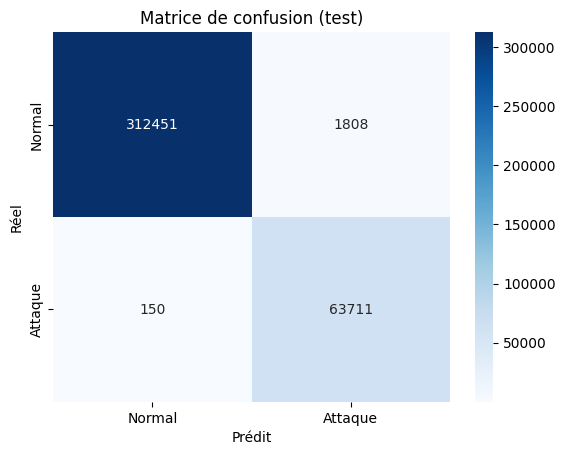

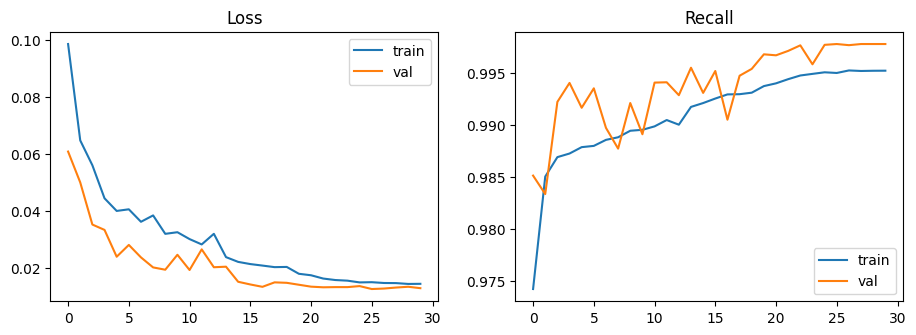

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score)
import matplotlib.pyplot as plt
import seaborn as sns

proba = model.predict(X_test, batch_size=4096).ravel()
pred = (proba > 0.5).astype(int)

print(classification_report(y_test, pred, target_names=["Normal", "Attaque"], digits=4))
print("ROC-AUC :", round(roc_auc_score(y_test, proba), 5))
print("PR-AUC  :", round(average_precision_score(y_test, proba), 5))

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print(f"Faux positifs : {fp} ({fp/(fp+tn):.4%} du trafic normal)")
print(f"Attaques manquées : {fn} ({fn/(fn+tp):.4%} des attaques)")

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attaque"], yticklabels=["Normal", "Attaque"])
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion (test)")
plt.show()

# Courbes d'apprentissage
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["recall"], label="train"); ax[1].plot(history.history["val_recall"], label="val")
ax[1].set_title("Recall"); ax[1].legend()
plt.show()

## 10. Baseline : Random Forest
Modèle de référence pour comparer au DNN. 100 arbres,
`class_weight="balanced"`. Sert à juger si le DNN apporte un gain réel.


In [ ]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score)

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)

# Entraînement
t0 = time.time()
rf.fit(X_train, y_train)
t_train_rf = time.time() - t0

# Inférence sur le test
t0 = time.time()
proba_rf = rf.predict_proba(X_test)[:, 1]
t_inf_rf = time.time() - t0
pred_rf = (proba_rf > 0.5).astype(int)

print(classification_report(y_test, pred_rf, target_names=["Normal", "Attaque"], digits=4))
print("ROC-AUC :", round(roc_auc_score(y_test, proba_rf), 5))
print("PR-AUC  :", round(average_precision_score(y_test, proba_rf), 5))

tn, fp, fn, tp = confusion_matrix(y_test, pred_rf).ravel()
print(f"Faux positifs : {fp} ({fp/(fp+tn):.4%})")
print(f"Attaques manquées : {fn} ({fn/(fn+tp):.4%})")
print(f"Temps d'entraînement : {t_train_rf:.1f} s")
print(f"Temps d'inférence (test, {len(X_test)} flux) : {t_inf_rf:.2f} s")

              precision    recall  f1-score   support

      Normal     0.9989    0.9993    0.9991    314259
     Attaque     0.9968    0.9948    0.9958     63861

    accuracy                         0.9986    378120
   macro avg     0.9979    0.9971    0.9975    378120
weighted avg     0.9986    0.9986    0.9986    378120

ROC-AUC : 0.99977
PR-AUC  : 0.99803
Faux positifs : 206 (0.0656%)
Attaques manquées : 333 (0.5214%)
Temps d'entraînement : 655.6 s
Temps d'inférence (test, 378120 flux) : 3.17 s


## 11. Comparaison DNN vs Random Forest
Tableau récapitulatif : précision, rappel, F1, faux positifs,
temps d'inférence pour les deux modèles.

In [ ]:
from sklearn.metrics import f1_score, recall_score, precision_score
import pandas as pd, time

t0 = time.time()
proba_dnn = model.predict(X_test, batch_size=4096, verbose=0).ravel()
t_inf_dnn = time.time() - t0
pred_dnn = (proba_dnn > 0.5).astype(int)

def resume(nom, y_pred, proba, t_inf):
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {
        "Modèle": nom,
        "Précision": round(precision_score(y_test, y_pred), 4),
        "Rappel": round(recall_score(y_test, y_pred), 4),
        "F1": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, proba), 5),
        "Faux positifs": fp,
        "Attaques manquées": fn,
        "Inférence (s)": round(t_inf, 2),
    }

tableau = pd.DataFrame([
    resume("DNN", pred_dnn, proba_dnn, t_inf_dnn),
    resume("Random Forest", pred_rf, proba_rf, t_inf_rf),
])
print(tableau.to_string(index=False))
tableau.to_csv(MODEL_DIR + "comparaison_binaire.csv", index=False)

       Modèle  Précision  Rappel     F1  ROC-AUC  Faux positifs  Attaques manquées  Inférence (s)
          DNN     0.9724  0.9977 0.9849  0.99988           1808                150           0.62
Random Forest     0.9968  0.9948 0.9958  0.99977            206                333           3.17


## 12. Réglage du seuil de décision (DNN binaire)
Le ROC-AUC quasi parfait (0.9999) montre que le modèle sépare bien
les classes — c'est le seuil par défaut (0.5) qui cause trop de
fausses alertes. Test de plusieurs seuils pour trouver le compromis.

In [ ]:
from sklearn.metrics import confusion_matrix

p_val = model.predict(X_val, batch_size=4096, verbose=0).ravel()
p_test = proba_dnn

print("seuil | FP test | manquées test | précision | rappel")
for t in [0.5, 0.7, 0.8, 0.9, 0.95, 0.98]:
    pred = (p_test > t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{t:5} | {fp:7} | {fn:13} | {tp/(tp+fp):.4f}    | {tp/(tp+fn):.4f}")

seuil | FP test | manquées test | précision | rappel
  0.5 |    1808 |           150 | 0.9724    | 0.9977
  0.7 |     461 |           653 | 0.9928    | 0.9898
  0.8 |     293 |           747 | 0.9954    | 0.9883
  0.9 |     256 |           900 | 0.9960    | 0.9859
 0.95 |     241 |          1011 | 0.9962    | 0.9842
 0.98 |     161 |          1542 | 0.9974    | 0.9759


## 13. Préparation des données pour le multiclasse
Récupération des étiquettes à 7 classes, encodage numérique
avec `LabelEncoder`. Les 7 classes : Bot, BruteForce, DDoS, DoS,
Normal, PortScan, WebAttack.

In [ ]:
from sklearn.preprocessing import LabelEncoder
import numpy as np, joblib

# Récupérer les étiquettes multiclasses via l'index conservé par train_test_split
ym_train = df.loc[y_train.index, "y_multi"]
ym_val   = df.loc[y_val.index,   "y_multi"]
ym_test  = df.loc[y_test.index,  "y_multi"]

# Retirer Infiltration / Heartbleed (y_multi = NaN)
m_tr, m_va, m_te = ym_train.notna().values, ym_val.notna().values, ym_test.notna().values

Xm_train, Xm_val, Xm_test = X_train[m_tr], X_val[m_va], X_test[m_te]

le = LabelEncoder().fit(ym_train[m_tr])
ym_train = le.transform(ym_train[m_tr])
ym_val   = le.transform(ym_val[m_va])
ym_test  = le.transform(ym_test[m_te])

joblib.dump(le, MODEL_DIR + "label_encoder.pkl")

print("Classes :", list(le.classes_))
print("Train :", Xm_train.shape, "| Val :", Xm_val.shape, "| Test :", Xm_test.shape)
print("\nEffectifs train par classe :")
for i, c in enumerate(le.classes_):
    print(f"  {c:11s} {np.sum(ym_train == i)}")

Classes : ['Bot', 'BruteForce', 'DDoS', 'DoS', 'Normal', 'PortScan', 'WebAttack']
Train : (1764521, 69) | Val : (378114, 69) | Test : (378116, 69)

Effectifs train par classe :
  Bot         1365
  BruteForce  6476
  DDoS        89623
  DoS         135572
  Normal      1466539
  PortScan    63473
  WebAttack   1473


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)
n_classes = len(le.classes_)

w = compute_class_weight("balanced", classes=np.arange(n_classes), y=ym_train)
w = np.sqrt(w)                       # adoucit les poids extrêmes
class_weight_m = {i: float(w[i]) for i in range(n_classes)}
print("class_weight :", {le.classes_[i]: round(v, 2) for i, v in class_weight_m.items()})

model_m = models.Sequential([
    layers.Input(shape=(Xm_train.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])

model_m.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cb = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5),
    callbacks.ModelCheckpoint(MODEL_DIR + "nids_dnn_multi.keras",
                              monitor="val_loss", save_best_only=True),
]

history_m = model_m.fit(
    Xm_train, ym_train,
    validation_data=(Xm_val, ym_val),
    epochs=40, batch_size=1024,
    class_weight=class_weight_m,
    callbacks=cb, verbose=2,
)

class_weight : {'Bot': 13.59, 'BruteForce': 6.24, 'DDoS': 1.68, 'DoS': 1.36, 'Normal': 0.41, 'PortScan': 1.99, 'WebAttack': 13.08}
Epoch 1/40
1724/1724 - 17s - 10ms/step - accuracy: 0.9567 - loss: 0.0952 - val_accuracy: 0.9654 - val_loss: 0.0861 - learning_rate: 0.0010
Epoch 2/40
1724/1724 - 6s - 4ms/step - accuracy: 0.9675 - loss: 0.0564 - val_accuracy: 0.9712 - val_loss: 0.0687 - learning_rate: 0.0010
Epoch 3/40
1724/1724 - 6s - 4ms/step - accuracy: 0.9699 - loss: 0.0499 - val_accuracy: 0.9755 - val_loss: 0.0662 - learning_rate: 0.0010
Epoch 4/40
1724/1724 - 6s - 4ms/step - accuracy: 0.9731 - loss: 0.0453 - val_accuracy: 0.9752 - val_loss: 0.0597 - learning_rate: 0.0010
Epoch 5/40
1724/1724 - 6s - 4ms/step - accuracy: 0.9800 - loss: 0.0384 - val_accuracy: 0.9846 - val_loss: 0.0439 - learning_rate: 0.0010
Epoch 6/40
1724/1724 - 6s - 4ms/step - accuracy: 0.9777 - loss: 0.0394 - val_accuracy: 0.9805 - val_loss: 0.0495 - learning_rate: 0.0010
Epoch 7/40
1724/1724 - 6s - 4ms/step - accura

## 14. DNN multiclasse — essai 1 (poids en racine carrée)
Architecture 69→256→128→64→7 (softmax). Premier essai de pondération
des classes.

**Résultat : F1 macro = 0.79** — trop de fausses alertes sur
Bot et WebAttack (poids trop agressifs)

              precision    recall  f1-score   support

         Bot     0.1261    0.9331    0.2222       284
  BruteForce     0.9708    0.9796    0.9752      1323
        DDoS     0.9976    0.9994    0.9985     19206
         DoS     0.9810    0.9966    0.9887     29036
      Normal     0.9996    0.9886    0.9941    314259
    PortScan     0.9880    0.9990    0.9935     13675
   WebAttack     0.2498    0.9670    0.3970       333

    accuracy                         0.9901    378116
   macro avg     0.7590    0.9805    0.7956    378116
weighted avg     0.9962    0.9901    0.9927    378116

F1 macro : 0.7956


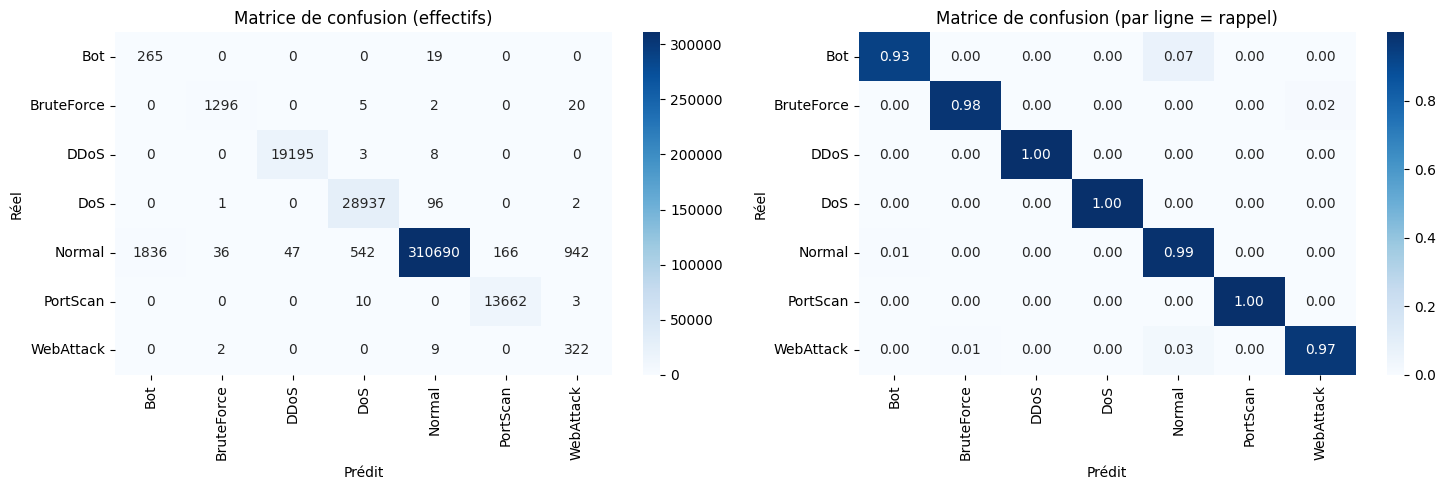

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt, seaborn as sns

proba_m = model_m.predict(Xm_test, batch_size=4096, verbose=0)
pred_m = proba_m.argmax(axis=1)

print(classification_report(ym_test, pred_m, target_names=le.classes_, digits=4))
print("F1 macro :", round(f1_score(ym_test, pred_m, average="macro"), 4))

cm = confusion_matrix(ym_test, pred_m)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=le.classes_, yticklabels=le.classes_)
ax[0].set_title("Matrice de confusion (effectifs)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=ax[1],
            xticklabels=le.classes_, yticklabels=le.classes_)
ax[1].set_title("Matrice de confusion (par ligne = rappel)")
for a in ax:
    a.set_xlabel("Prédit"); a.set_ylabel("Réel")
plt.tight_layout(); plt.show()

## 15. DNN multiclasse — version retenue (poids adoucis, exposant 0.25)
Même architecture, poids de classes adoucis pour un meilleur équilibre
précision/rappel sur les classes rares.

**✅ Modèle final du projet**


In [ ]:
tf.keras.utils.set_random_seed(42)

w = compute_class_weight("balanced", classes=np.arange(n_classes), y=ym_train)
w = w ** 0.25                       # poids très adoucis
class_weight_m2 = {i: float(w[i]) for i in range(n_classes)}
print({le.classes_[i]: round(v, 2) for i, v in class_weight_m2.items()})

model_m2 = models.Sequential([
    layers.Input(shape=(Xm_train.shape[1],)),
    layers.Dense(256, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
model_m2.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cb2 = [callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
       callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5),
       callbacks.ModelCheckpoint(MODEL_DIR + "nids_dnn_multi_v2.keras",
                                 monitor="val_loss", save_best_only=True)]

model_m2.fit(Xm_train, ym_train, validation_data=(Xm_val, ym_val),
             epochs=40, batch_size=1024, class_weight=class_weight_m2,
             callbacks=cb2, verbose=2)

pred2 = model_m2.predict(Xm_test, batch_size=4096, verbose=0).argmax(axis=1)
print(classification_report(ym_test, pred2, target_names=le.classes_, digits=4))
print("F1 macro :", round(f1_score(ym_test, pred2, average="macro"), 4))

{'Bot': 3.69, 'BruteForce': 2.5, 'DDoS': 1.3, 'DoS': 1.17, 'Normal': 0.64, 'PortScan': 1.41, 'WebAttack': 3.62}
Epoch 1/40
1724/1724 - 16s - 9ms/step - accuracy: 0.9671 - loss: 0.0798 - val_accuracy: 0.9736 - val_loss: 0.0549 - learning_rate: 0.0010
Epoch 2/40
1724/1724 - 8s - 4ms/step - accuracy: 0.9756 - loss: 0.0479 - val_accuracy: 0.9768 - val_loss: 0.0449 - learning_rate: 0.0010
Epoch 3/40
1724/1724 - 8s - 4ms/step - accuracy: 0.9786 - loss: 0.0420 - val_accuracy: 0.9836 - val_loss: 0.0374 - learning_rate: 0.0010
Epoch 4/40
1724/1724 - 8s - 4ms/step - accuracy: 0.9865 - loss: 0.0317 - val_accuracy: 0.9900 - val_loss: 0.0253 - learning_rate: 0.0010
Epoch 5/40
1724/1724 - 8s - 4ms/step - accuracy: 0.9892 - loss: 0.0267 - val_accuracy: 0.9882 - val_loss: 0.0281 - learning_rate: 0.0010
Epoch 6/40
1724/1724 - 8s - 4ms/step - accuracy: 0.9879 - loss: 0.0280 - val_accuracy: 0.9917 - val_loss: 0.0200 - learning_rate: 0.0010
Epoch 7/40
1724/1724 - 8s - 4ms/step - accuracy: 0.9892 - loss: 0

In [ ]:
pred2 = model_m2.predict(Xm_test, batch_size=4096, verbose=0).argmax(axis=1)
cm = confusion_matrix(ym_test, pred2)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=le.classes_, yticklabels=le.classes_)
ax[0].set_title("Effectifs")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=ax[1],
            xticklabels=le.classes_, yticklabels=le.classes_)
ax[1].set_title("Normalisée par ligne (rappel)")
for a in ax:
    a.set_xlabel("Prédit"); a.set_ylabel("Réel")
plt.tight_layout(); plt.show()

model_m2.save(MODEL_DIR + "nids_dnn_multi_final.keras")

In [ ]:
pv = model_m2.predict(Xm_val, batch_size=4096, verbose=0)
pt = model_m2.predict(Xm_test, batch_size=4096, verbose=0)
iw = list(le.classes_).index("WebAttack")
ib = list(le.classes_).index("Bot")
iN = list(le.classes_).index("Normal")

def predire(p, seuil_web, seuil_bot):
    pred = p.argmax(axis=1)
    # si WebAttack/Bot prédit avec une probabilité trop faible -> Normal
    pred[(pred == iw) & (p[:, iw] < seuil_web)] = iN
    pred[(pred == ib) & (p[:, ib] < seuil_bot)] = iN
    return pred

print("seuil_web | seuil_bot | F1 macro (val)")
for sw in [0.5, 0.7, 0.9, 0.97]:
    for sb in [0.5, 0.7, 0.9]:
        print(f"{sw:9} | {sb:9} | {f1_score(ym_val, predire(pv, sw, sb), average='macro'):.4f}")

In [ ]:
import joblib
from tensorflow.keras.models import load_model

model_bin = load_model(MODEL_DIR + "nids_dnn_bin.keras")
SEUIL = 0.8

# Prédictions sur le test multiclasse (flux avec étiquette connue)
p_bin   = model_bin.predict(Xm_test, batch_size=4096, verbose=0).ravel()
p_multi = model_m2.predict(Xm_test, batch_size=4096, verbose=0)
iN = list(le.classes_).index("Normal")

pred = np.full(len(Xm_test), iN)
att = p_bin > SEUIL
# type d'attaque = meilleure classe parmi les classes d'attaque (Normal exclu)
p_att = p_multi.copy(); p_att[:, iN] = -1
pred[att] = p_att[att].argmax(axis=1)

print(classification_report(ym_test, pred, target_names=le.classes_, digits=4))
print("F1 macro (2 étages) :", round(f1_score(ym_test, pred, average="macro"), 4))


              precision    recall  f1-score   support

         Bot     0.9727    0.3768    0.5431       284
  BruteForce     0.9856    0.9841    0.9849      1323
        DDoS     0.9996    0.9984    0.9990     19206
         DoS     0.9958    0.9923    0.9941     29036
      Normal     0.9976    0.9991    0.9984    314259
    PortScan     0.9889    0.9993    0.9941     13675
   WebAttack     0.8500    0.1021    0.1823       333

    accuracy                         0.9972    378116
   macro avg     0.9700    0.7789    0.8137    378116
weighted avg     0.9971    0.9972    0.9968    378116

F1 macro (2 étages) : 0.8137


In [ ]:
import joblib
joblib.dump(0.8, MODEL_DIR + "seuil.pkl")
model_m2.save(MODEL_DIR + "nids_dnn_multi_final.keras")
print(sorted(os.listdir(MODEL_DIR)))

['columns.pkl', 'comparaison_binaire.csv', 'label_encoder.pkl', 'nids_dnn_bin.keras', 'nids_dnn_multi.keras', 'nids_dnn_multi_final.keras', 'nids_dnn_multi_v2.keras', 'scaler.pkl', 'seuil.pkl']


# Figer l’environnement (notebook)

In [ ]:
import sys, tensorflow as tf, sklearn, pandas as pd, numpy as np, joblib
print("python      ", sys.version.split()[0])
print("tensorflow  ", tf.__version__)
print("keras       ", tf.keras.__version__)
print("scikit-learn", sklearn.__version__)
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("joblib      ", joblib.__version__)

python       3.13.15
tensorflow   2.21.0
keras        3.13.2
scikit-learn 1.6.1
pandas       2.2.3
numpy        2.1.3
joblib       1.6.0


In [ ]:
  # =====================================================================
  # CELLULE À AJOUTER À LA TOUTE FIN DU NOTEBOOK (après la cellule seuil.pkl)
  # Génère le jeu de référence du test de non-régression.
  # Prérequis en mémoire : df, feature_cols, scaler, le, iN, SEUIL,
  #   y_test, m_te, ym_test, Xm_test, model_bin, model_m2, n_classes, MODEL_DIR
  # =====================================================================
  import joblib, numpy as np, pandas as pd

  # 1. Index (dans df) des lignes qui composent Xm_test
  idx_test_multi = y_test.index[m_te]

  # 2. Échantillon stratifié : jusqu'à 15 flux par classe (les classes rares sont couvertes)
  rng = np.random.RandomState(42)
  pos = np.sort(np.concatenate([
      rng.choice(np.where(ym_test == k)[0],
                size=min(15, int((ym_test == k).sum())), replace=False)
      for k in range(n_classes)
  ]))

  # 3. Flux BRUTS (nettoyés mais NON normalisés) : c'est ce que recevra predict_nids.py
  ref_raw = df.loc[idx_test_multi[pos], feature_cols].copy()

  # 4. Vérification : normaliser ces lignes brutes redonne bien Xm_test[pos]
  X_ref = scaler.transform(ref_raw).astype("float32")
  assert np.allclose(X_ref, Xm_test[pos], atol=1e-5), "Les lignes brutes ne correspondent pas à Xm_test"

  # 5. Sorties attendues avec la logique 2 étages du notebook
  p_bin_ref   = model_bin.predict(X_ref, verbose=0).ravel()
  p_multi_ref = model_m2.predict(X_ref, verbose=0)

  pred = np.full(len(X_ref), iN)
  att = p_bin_ref > SEUIL
  p_att = p_multi_ref.copy(); p_att[:, iN] = -1          # Normal exclu
  pred[att] = p_att[att].argmax(axis=1)
  labels_ref = le.inverse_transform(pred)

  # 6. Sauvegarde
  ref_raw.to_csv(MODEL_DIR + "ref_raw.csv", index=False)
  joblib.dump({
      "p_bin": p_bin_ref,
      "p_multi": p_multi_ref,
      "labels": labels_ref,
      "labels_reels": le.inverse_transform(ym_test[pos]),
  }, MODEL_DIR + "ref_expected.pkl")

  print("Lignes de référence :", len(ref_raw))
  print(pd.Series(labels_ref).value_counts())
  print("Accord avec les vraies étiquettes :", (labels_ref == le.inverse_transform(ym_test[pos])).mean().round(3))
  print(sorted(os.listdir(MODEL_DIR)))

Lignes de référence : 105
Normal        36
BruteForce    15
DoS           15
PortScan      15
DDoS          15
Bot            7
WebAttack      2
Name: count, dtype: int64
Accord avec les vraies étiquettes : 0.8
['columns.pkl', 'comparaison_binaire.csv', 'label_encoder.pkl', 'nids_dnn_bin.keras', 'nids_dnn_multi.keras', 'nids_dnn_multi_final.keras', 'nids_dnn_multi_v2.keras', 'ref_expected.pkl', 'ref_raw.csv', 'scaler.pkl', 'seuil.pkl']
